# terrio quickstart

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/opengeos/terrio/blob/main/docs/notebooks/quickstart.ipynb)

[terrio](https://terrio.opengeos.org) reads, writes, converts and reprojects geospatial rasters, vector data and point clouds in pure Rust, without installing GDAL. This notebook uses its Python package on real data: a USGS elevation COG read in place over HTTP, a Landsat image, and the world's countries.

## Install

The wheel needs only NumPy; matplotlib is for the plots.

In [1]:
%pip install -q terrio matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import terrio

terrio.__version__

'0.1.1'

## A cloud-optimized GeoTIFF, read in place

A 1 arc-second USGS 3DEP elevation tile (about 50 MB) on Amazon S3. Opened lazily, terrio fetches only the header; reads fetch only the tiles they need, with HTTP range requests.

In [3]:
url = "https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/1/TIFF/current/n40w106/USGS_1_n40w106.tif"
dem = terrio.open_raster(url, lazy=True)
print(dem.width, dem.height, dem.dtype, dem.crs)
print("overviews:", dem.overviews)

3612 3612 float32 EPSG:4269
overviews: [(1806, 1806), (903, 903), (451, 451)]


The smallest overview is a quick look at the whole tile:

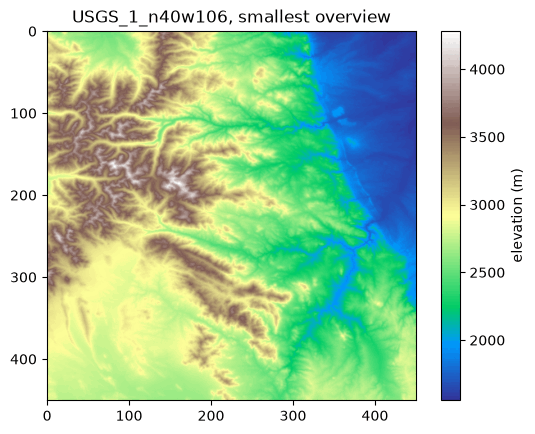

In [4]:
overview = dem.read(1, overview=len(dem.overviews) - 1)
plt.imshow(np.where(overview == dem.nodata, np.nan, overview), cmap="terrain")
plt.colorbar(label="elevation (m)")
plt.title("USGS_1_n40w106, smallest overview");

A full-resolution 1024 × 1024 window over the Front Range between Estes Park and Lyons, Colorado, written to a local GeoTIFF:

In [5]:
terrio.convert(url, "frontrange.tif", srcwin=(2000, 1500, 1024, 1024))
terrio.info("frontrange.tif", stats=True)["bands"][0]["statistics"]

{'min': 1834.3316650390625,
 'max': 3640.29052734375,
 'mean': 2422.2508442005283,
 'std_dev': 244.88005806153174,
 'valid_count': 1048576}

## Terrain analysis

`terrio.dem` matches `gdaldem` pixel for pixel.

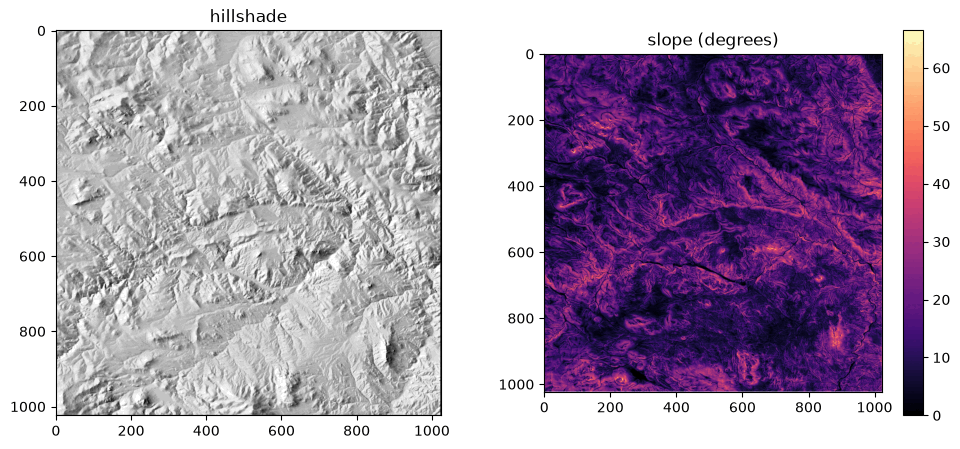

In [6]:
shade = terrio.dem("frontrange.tif", "hillshade", multidirectional=True)
slope = terrio.dem("frontrange.tif", "slope")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(shade.read(1), cmap="gray")
axes[0].set_title("hillshade")
im = axes[1].imshow(np.ma.masked_equal(slope.read(1), slope.nodata), cmap="magma")
axes[1].set_title("slope (degrees)")
fig.colorbar(im, ax=axes[1]);

## Reprojection

`terrio.warp` is `gdalwarp`: here to UTM zone 13N at 30 m with bilinear resampling.

In [7]:
utm = terrio.warp("frontrange.tif", "frontrange_utm.tif", t_srs="EPSG:32613", tr=(30, 30), resampling="bilinear")
print(utm.width, utm.height, utm.crs)
print(utm.transform)

819 1055 EPSG:32613
(461534.33989742654, 30.0, 0.0, 4381792.967684969, 0.0, -30.0)


## A multispectral image and raster algebra

A Landsat 7 scene of San Francisco Bay (bands 1 to 3 are near infrared, red and green). `terrio.calc` is `gdal_calc.py`, with NumPy's typing rules.

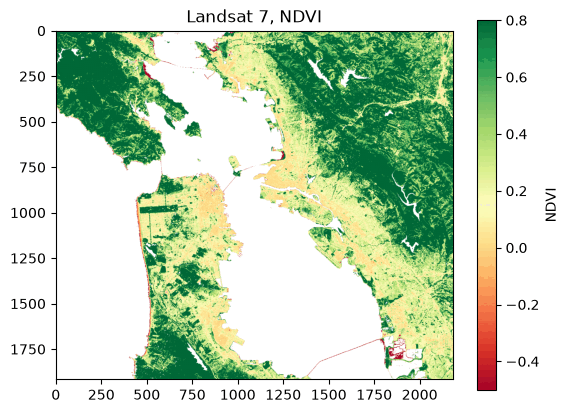

In [8]:
landsat_url = "https://raw.githubusercontent.com/opengeos/data/main/raster/landsat7.tif"
terrio.convert(landsat_url, "landsat7.tif")
# The image declares 0 as nodata, but in 8 bits the red band is 0 over dense vegetation, so
# ignore the nodata value (hide_nodata, gdal_calc.py's --hideNoData). Water, 0 in both bands,
# divides 0 by 0 and is left as NaN.
ndvi = terrio.calc("(A - B * 1.0) / (A + B * 1.0)", A="landsat7.tif", A_band=1, B="landsat7.tif", B_band=2, type="Float32", hide_nodata=True)
values = ndvi.read(1)
plt.imshow(values, cmap="RdYlGn", vmin=-0.5, vmax=0.8)
plt.colorbar(label="NDVI")
plt.title("Landsat 7, NDVI");

## Vector data

The world's countries as GeoJSON, read straight from a URL.

In [9]:
countries = terrio.open_vector("https://raw.githubusercontent.com/opengeos/data/main/world/countries.geojson")
layer = countries.layers[0]
print(layer.name, layer.geometry_type, len(layer), layer.crs)
print(layer.fields)

countries MultiPolygon 179 EPSG:4326
{'id': 'Text', 'name': 'Text'}


Filter with SQL, reproject, and write to other formats:

In [10]:
terrio.convert(
    "https://raw.githubusercontent.com/opengeos/data/main/world/countries.geojson",
    "united.gpkg",
    where="name LIKE 'United%'",
    t_srs="EPSG:3857",
)
united = terrio.open_vector("united.gpkg").layers[0]
print(united.crs, [f["properties"]["name"] for f in united.to_geojson()["features"]])

EPSG:3857 ['United Arab Emirates', 'United Kingdom', 'United Republic of Tanzania', 'United States of America']


In [11]:
for ext in ["fgb", "parquet", "shp", "kml"]:
    terrio.write_vector(layer, f"countries.{ext}")
    back = terrio.open_vector(f"countries.{ext}").layers[0]
    print(f"countries.{ext}: {len(back)} features")

countries.fgb: 179 features
countries.parquet: 179 features
countries.shp: 179 features
countries.kml: 179 features


A quick plot of the polygons:

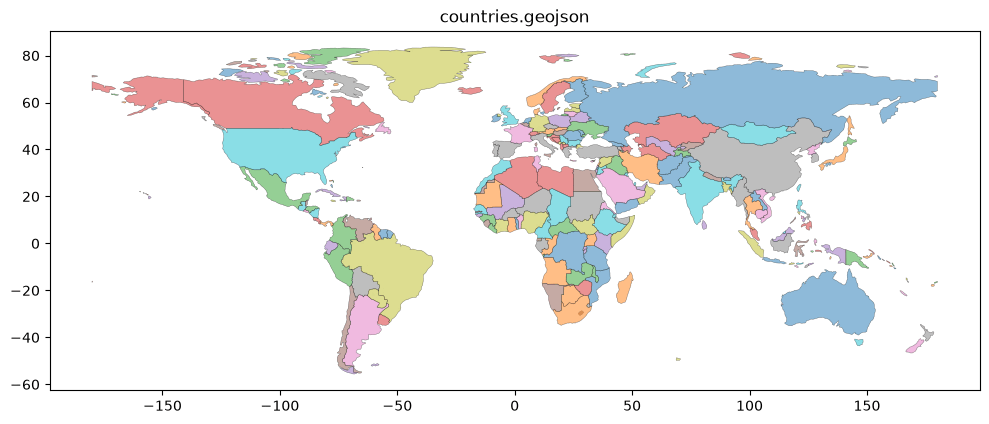

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
for feature in layer.to_geojson()["features"]:
    geometry = feature["geometry"]
    polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    for polygon in polygons:
        ring = np.array(polygon[0])
        ax.fill(ring[:, 0], ring[:, 1], alpha=0.5, edgecolor="k", linewidth=0.3)
ax.set_aspect("equal")
ax.set_title("countries.geojson");

## Rasterize

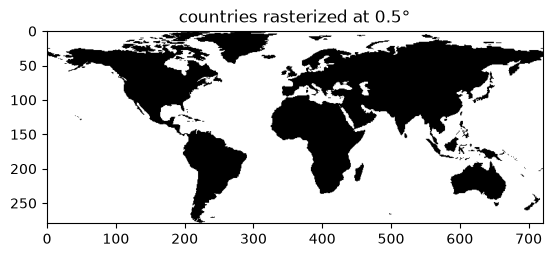

In [13]:
mask = terrio.rasterize(layer, burn=1, tr=(0.5, 0.5), ot="Byte", init=0)
plt.imshow(mask.read(1), cmap="Greys")
plt.title("countries rasterized at 0.5°");

## Coordinates

Transformations use the operations GDAL picks, for every EPSG CRS.

In [14]:
xs, ys = terrio.transform_points([-105.2705], [40.015], "EPSG:4326", "EPSG:32613")
print(xs[0], ys[0])

476915.2393449761 4429457.112618952


## Next

- [Documentation](https://terrio.opengeos.org)
- [Python API](https://terrio.opengeos.org/python/)
- [Try terrio in the browser](https://terrio.opengeos.org/playground/)